#**Colab Intro**

##2.
### *Sumowanie ciągu geometrycznego dla $n$ wyrazów*

Ciąg geometryczny to ciąg liczbowy, w którym każdy kolejny wyraz powstaje pomnożeniem poprzedniego przez stałą wartość $q$ (tzw. iloraz ciągu).

#### Wzór ogólny na $n$-ty wyraz:
$$
a_n = a_1 \cdot q^{n-1}
$$

#### Wzór na sumę $S_n$ pierwszych $n$ wyrazów:
* Dla $q \neq 1$:
  $$
  S_n = a_1 \cdot \frac{1 - q^n}{1 - q}
  $$
* Dla $q = 1$:
  $$
  S_n = n \cdot a_1
  $$

## *Kodowanie*


##3.






In [ ]:
a=2+2
print(a)

4


##4.

In [ ]:
import math

π = math.pi
x = π ** π
print(x)

36.4621596072079


##5.

In [ ]:
suma = 0
for i in range(1, 101):
    suma += i**2
print(suma)

338350


##6.

In [ ]:
suma

with open("colab_wynik.txt", "w", encoding="utf-8") as f:
    f.write(str(suma))

##7.

<>:12: SyntaxWarning: invalid escape sequence '\i'
<>:12: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_16332/1135669276.py:12: SyntaxWarning: invalid escape sequence '\i'
  ax.set_title('Wykres funkcji $y = k^2$ dla $k \in [1, 20]$')


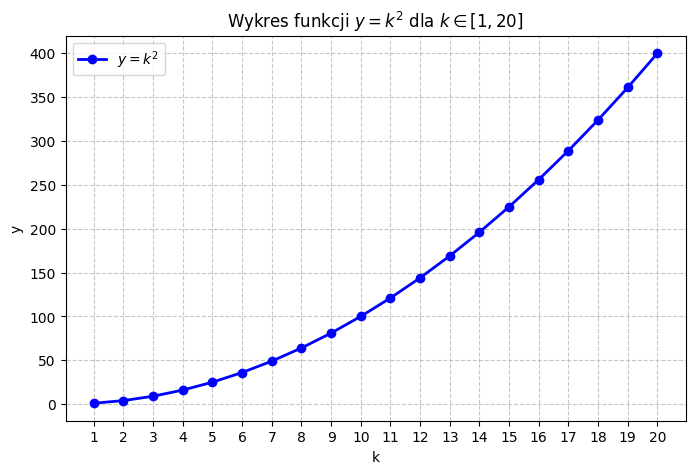

In [ ]:
import matplotlib.pyplot as plt

# Definiowanie wartości k oraz obliczanie y = k^2
k = list(range(1, 21))
y = [i**2 for i in k]

# Tworzenie wykresu i przypisanie go do zmiennej `fig`
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k, y, marker='o', color='b', linestyle='-', linewidth=2, label='$y = k^2$')

# Opisy osi i tytuł
ax.set_title('Wykres funkcji $y = k^2$ dla $k \in [1, 20]$')
ax.set_xlabel('k')
ax.set_ylabel('y')
ax.set_xticks(range(1, 21))
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend()

# Wyświetlenie wykresu
plt.show()

##8.

In [ ]:
from google.colab import files

fig.savefig('wykres.png', dpi=300, bbox_inches='tight')

##9.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from scipy.integrate import solve_ivp
from IPython.display import HTML, display
import base64


g = 9.81
L = 1.0

def pendulum_ode(t, y):
    theta, omega = y
    dtheta_dt = omega
    domega_dt = -(g / L) * np.sin(theta)
    return [dtheta_dt, domega_dt]


y0 = [np.pi / 4, 0.0]
fps = 30
duration = 8
t_eval = np.linspace(0, duration, fps * duration)


solution = solve_ivp(pendulum_ode, (0, duration), y0, t_eval=t_eval, method='RK45')
theta = solution.y[0]


x = L * np.sin(theta)
y = -L * np.cos(theta)


fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-L * 1.2, L * 1.2)
ax.set_ylim(-L * 1.2, L * 0.3)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title("Symulacja Wahadła Matematycznego", fontsize=12, pad=12)
ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")


line, = ax.plot([], [], 'o-', lw=3, color='#1f77b4', markersize=14, markerfacecolor='#ff7f0e', markeredgecolor='#333')
trace, = ax.plot([], [], '-', color='#1f77b4', alpha=0.3, lw=1.5)

def init():
    line.set_data([], [])
    trace.set_data([], [])
    return line, trace

def update(frame):
    line.set_data([0, x[frame]], [0, y[frame]])
    start_frame = max(0, frame - 20)
    trace.set_data(x[start_frame:frame], y[start_frame:frame])
    return line, trace

anim = FuncAnimation(fig, update, frames=len(t_eval), init_func=init, blit=True)

output_filename = "video.mp4"
writer = FFMpegWriter(fps=fps, metadata=dict(artist='Google Colab'), bitrate=1800)
anim.save(output_filename, writer=writer)
plt.close(fig)


with open(output_filename, "rb") as f:
    video_bytes = f.read()

video_b64 = base64.b64encode(video_bytes).decode('utf-8')
video_html = f'''
<video width="500" height="500" controls autoplay loop style="border: 1px solid #ddd; border-radius: 8px;">
    <source src="data:video/mp4;base64,{video_b64}" type="video/mp4">
    Twoja przeglądarka nie obsługuje odtwarzacza HTML5.
</video>
'''

display(HTML(video_html))
print(f"Plik został pomyślnie zapisany jako: {output_filename}")

Plik został pomyślnie zapisany jako: video.mp4


##10.

In [ ]:
!ffmpeg -y -i video.mp4 -vf "fps=30,scale=500:-1:flags=lanczos" video.gif

print("Plik został pomyślnie zapisany jako: video.gif")

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

##11.

/tmp/ipykernel_16332/2942871474.py:8: RuntimeWarning: divide by zero encountered in log
  x = np.sin(t) * np.log(t)
/tmp/ipykernel_16332/2942871474.py:8: RuntimeWarning: invalid value encountered in multiply
  x = np.sin(t) * np.log(t)


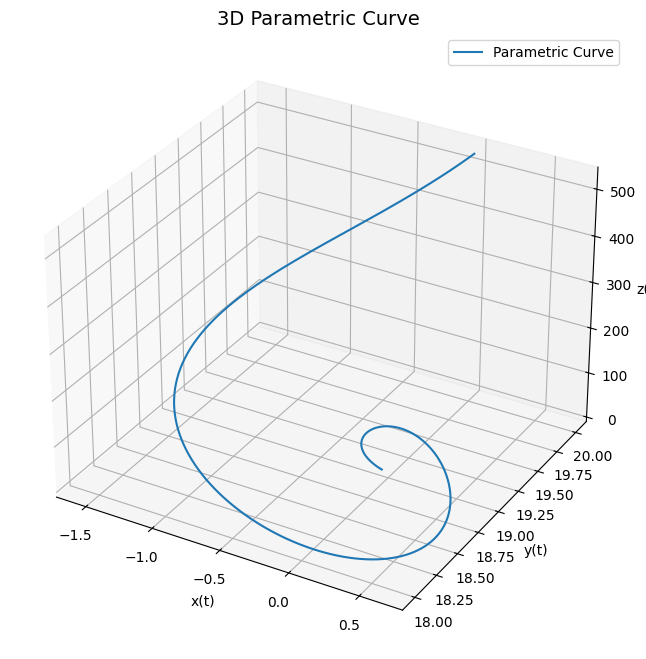

In [ ]:
# Correcting the label for rendering issue in matplotlib mathtext
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Parametric equations
t = np.linspace(0, 2 * np.pi, 500)
x = np.sin(t) * np.log(t)
y = np.tanh(t) * np.cos(t) + 19
z = np.exp(t)

# 3D Plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Parametric Curve")
ax.set_title("3D Parametric Curve", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()
plt.savefig('parametric_curve.png', dpi=300, bbox_inches='tight')
plt.show()